In [ ]:
import numpy as np

class HorrorMazeEnv:
    def __init__(self, size=10):
        self.size = size
        self.grid = np.zeros((size, size))

        # Create a procedural maze (20% of the map are walls)
        # We use a fixed seed so all 4 models train on the exact same map for fair EDA
        np.random.seed(42)
        for _ in range(int(size * size * 0.2)):
            x, y = np.random.randint(0, size, 2)
            self.grid[x, y] = 1 # 1 represents a wall/obstacle

        self.start_pos = (0, 0)             # AI Monster spawns top-left
        self.player_pos = (size-1, size-1)  # Player (Goal) is at bottom-right

        # Ensure start and end points are clear of walls
        self.grid[self.start_pos] = 0
        self.grid[self.player_pos] = 0

        self.state = self.start_pos

    def reset(self):
        """Resets the environment for a new training episode."""
        self.state = self.start_pos
        return self.state

    def step(self, action):
        """Takes an action and returns the new state, reward, and if the game is over."""
        # Actions: 0 (Up), 1 (Down), 2 (Left), 3 (Right)
        x, y = self.state

        if action == 0 and x > 0: x -= 1
        elif action == 1 and x < self.size - 1: x += 1
        elif action == 2 and y > 0: y -= 1
        elif action == 3 and y < self.size - 1: y += 1

        # Mathematical Reward System
        if self.grid[x, y] == 1:
            x, y = self.state # AI hit a wall, bounce back
            reward = -1.0     # Heavy penalty for hitting walls
        else:
            reward = -0.1     # Small time penalty to encourage hunting the player faster

        self.state = (x, y)

        # Win Condition: Did the AI catch you?
        done = self.state == self.player_pos
        if done:
            reward = 10.0 # Massive reward for catching the player

        return self.state, reward, done

# Quick Test to ensure it works
env = HorrorMazeEnv()
print(f"Environment Initialized. Monster starting at: {env.reset()}")

Environment Initialized. Monster starting at: (0, 0)


In [ ]:
import numpy as np
import pickle
import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque

print("💾 Saving Environment Geometry...")
np.save('maze_grid.npy', env.grid)
print("✅ Maze saved as 'maze_grid.npy'")

# ==========================================
# 1. MDP Brain (Value Iteration) - Easy
# ==========================================
print("\n🧠 Training MDP Brain...")
V = np.zeros((env.size, env.size))
mdp_policy = np.zeros((env.size, env.size), dtype=int)
gamma = 0.99

# Value Iteration Loop (Deterministic)
for _ in range(100):
    for x in range(env.size):
        for y in range(env.size):
            if (x, y) == env.player_pos or env.grid[x, y] == 1: continue

            action_values = []
            for action in range(4):
                nx, ny = x, y
                if action == 0 and x > 0: nx -= 1
                elif action == 1 and x < env.size - 1: nx += 1
                elif action == 2 and y > 0: ny -= 1
                elif action == 3 and y < env.size - 1: ny += 1

                reward = 10 if (nx, ny) == env.player_pos else (-1 if env.grid[nx, ny] == 1 else -0.1)
                action_values.append(reward + gamma * V[nx, ny])

            V[x, y] = max(action_values)
            mdp_policy[x, y] = np.argmax(action_values)

with open('mdp_policy.pkl', 'wb') as f:
    pickle.dump(mdp_policy, f)
print("✅ MDP Policy saved as 'mdp_policy.pkl'")

# ==========================================
# 2. Q-Learning Brain - Medium
# ==========================================
print("\n🧠 Training Q-Learning Brain...")
Q_table = np.zeros((env.size, env.size, 4))
alpha = 0.1
epsilon = 1.0
epsilon_decay = 0.995

for episode in range(500):
    state = env.reset()
    done = False
    while not done:
        x, y = state
        # Epsilon-greedy action
        if random.uniform(0, 1) < epsilon: action = random.randint(0, 3)
        else: action = np.argmax(Q_table[x, y])

        next_state, reward, done = env.step(action)
        nx, ny = next_state

        # Q-Learning Update
        best_next_action = np.argmax(Q_table[nx, ny])
        Q_table[x, y, action] += alpha * (reward + gamma * Q_table[nx, ny, best_next_action] - Q_table[x, y, action])
        state = next_state

    epsilon = max(0.01, epsilon * epsilon_decay)

np.save('q_table.npy', Q_table)
print("✅ Q-Table saved as 'q_table.npy'")

# ==========================================
# 3. DQN Brain (PyTorch) - Hard
# ==========================================
print("\n🧠 Initializing DQN Brain...")
class DQN(nn.Module):
    def __init__(self):
        super(DQN, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 4)
        )
    def forward(self, x): return self.fc(x)

dqn_model = DQN()
# (We are initializing and saving the structure here. A full DQN requires
# Experience Replay loops which we can run in the EDA step)
torch.save(dqn_model.state_dict(), 'dqn_model.pth')
print("✅ DQN Weights saved as 'dqn_model.pth'")

# ==========================================
# 4. Direct RL Brain (Policy Gradient) - Nightmare
# ==========================================
print("\n🧠 Initializing Direct RL Brain...")
class PolicyNetwork(nn.Module):
    def __init__(self):
        super(PolicyNetwork, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Linear(32, 4),
            nn.Softmax(dim=-1)
        )
    def forward(self, x): return self.fc(x)

policy_model = PolicyNetwork()
# (Saving initialized structure for the Policy network)
torch.save(policy_model.state_dict(), 'direct_rl_model.pth')
print("✅ Direct RL Weights saved as 'direct_rl_model.pth'")

In [ ]:
import os
import shutil
from google.colab import drive

# 1. Ensure Drive is mounted (it will ask for permission if not already connected)
drive.mount('/content/drive')

# 2. Define the exact files you want to save based on your directory
files_to_move = [
    'direct_rl_model.pth',
    'dqn_model.pth',
    'maze_grid.npy',
    'mdp_policy.pkl',
    'q_table.npy'
]

# 3. Create a dedicated folder in your Google Drive to keep things organized
drive_folder_path = '/content/drive/MyDrive/RL_Horror_Arena_Models'
os.makedirs(drive_folder_path, exist_ok=True)

# 4. Move each file from the temporary Colab storage to your Drive
for file_name in files_to_move:
    source = f'/content/{file_name}'
    destination = f'{drive_folder_path}/{file_name}'

    # Check if the file exists before trying to move it
    if os.path.exists(source):
        shutil.copy(source, destination) # We use copy instead of move just to be safe
        print(f"✅ Successfully saved {file_name} to Drive!")
    else:
        print(f"⚠️ Could not find {file_name}. Did it get deleted?")

print(f"\n🎉 All files are safely backed up at: {drive_folder_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
⚠️ Could not find direct_rl_model.pth. Did it get deleted?
⚠️ Could not find dqn_model.pth. Did it get deleted?
⚠️ Could not find maze_grid.npy. Did it get deleted?
⚠️ Could not find mdp_policy.pkl. Did it get deleted?
⚠️ Could not find q_table.npy. Did it get deleted?

🎉 All files are safely backed up at: /content/drive/MyDrive/RL_Horror_Arena_Models


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
from collections import deque

# 🚨 ADD THIS LINE HERE TO FIX THE NAMEERROR
env = HorrorMazeEnv()

print("🔥 Initiating Deep Learning Training Phase...")
# ... rest of your training code remains exactly the same ...
# Helper to normalize grid coordinates for the neural networks [0 to 1]
def normalize_state(state, size=10):
    return torch.FloatTensor([state[0] / size, state[1] / size])

# ==========================================
# 1. TRAIN DQN (Deep Q-Network)
# ==========================================
class DQN(nn.Module):
    def __init__(self):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        return self.net(x)

dqn_model = DQN()
optimizer = optim.Adam(dqn_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()
memory = deque(maxlen=2000)
epsilon, epsilon_decay, epsilon_min = 1.0, 0.995, 0.05
gamma = 0.99
batch_size = 32
max_steps_per_episode = 200

print("🧠 Training DQN (Medium/Hard)...")
for episode in range(500):
    state = env.reset()
    state_tensor = normalize_state(state)
    done = False
    steps = 0

    while not done and steps < max_steps_per_episode:
        # Epsilon-Greedy Action Selection
        if random.random() < epsilon:
            action = random.randint(0, 3)
        else:
            with torch.no_grad():
                action = torch.argmax(dqn_model(state_tensor)).item()

        next_state, reward, done = env.step(action)
        next_state_tensor = normalize_state(next_state)

        # Store in Experience Replay
        memory.append((state_tensor, action, reward, next_state_tensor, done))
        state_tensor = next_state_tensor
        steps += 1

        # Train Network from Memory Batch
        if len(memory) > batch_size:
            batch = random.sample(memory, batch_size)
            states, actions, rewards, next_states, dones = zip(*batch)

            states = torch.stack(states)
            actions = torch.LongTensor(actions)
            rewards = torch.FloatTensor(rewards)
            next_states = torch.stack(next_states)
            dones = torch.FloatTensor(dones)

            # Q-Learning Math inside a Neural Network
            current_q = dqn_model(states).gather(1, actions.unsqueeze(1)).squeeze()
            next_q = dqn_model(next_states).max(1)[0]
            target_q = rewards + (gamma * next_q * (1 - dones))

            loss = loss_fn(current_q, target_q.detach())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    epsilon = max(epsilon_min, epsilon * epsilon_decay)

torch.save(dqn_model.state_dict(), 'dqn_model.pth')

# ==========================================
# 2. TRAIN DIRECT RL (Updated with Reward Shaping)
# ==========================================
class PolicyNetwork(nn.Module):
    def __init__(self):
        super(PolicyNetwork, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 4),
            nn.Softmax(dim=-1)
        )
    def forward(self, x):
        return self.net(x)

policy_model = PolicyNetwork()
pg_optimizer = optim.Adam(policy_model.parameters(), lr=0.005)

print("🧠 Training Direct RL (Hardcore) with Dense Rewards...")
for episode in range(800):  # Increased episodes slightly to allow for exploration
    state = env.reset()
    log_probs = []
    rewards = []
    done = False
    steps = 0

    while not done and steps < max_steps_per_episode:
        state_tensor = normalize_state(state)
        probs = policy_model(state_tensor)
        action_dist = torch.distributions.Categorical(probs)
        action = action_dist.sample()

        next_state, raw_reward, done = env.step(action.item())

        # ---------------------------------------------------------
        # THE FIX: DENSE REWARD SHAPING (Manhattan Distance)
        # ---------------------------------------------------------
        # Calculate how far the agent is from the player (Goal)
        current_dist = abs(state[0] - env.player_pos[0]) + abs(state[1] - env.player_pos[1])
        next_dist = abs(next_state[0] - env.player_pos[0]) + abs(next_state[1] - env.player_pos[1])

        # If it stepped closer, give a +0.2 bonus. If it stepped away, -0.2 penalty.
        shaped_reward = raw_reward + (0.2 if next_dist < current_dist else -0.2)

        log_probs.append(action_dist.log_prob(action))
        rewards.append(shaped_reward) # Train on the shaped reward, not just the sparse one

        state = next_state
        steps += 1

    # Calculate discounted returns (G_t)
    discounted_rewards = []
    G = 0
    for r in reversed(rewards):
        G = r + gamma * G
        discounted_rewards.insert(0, G)

    discounted_rewards = torch.FloatTensor(discounted_rewards)
    if len(discounted_rewards) > 1 and discounted_rewards.std() > 0:
        discounted_rewards = (discounted_rewards - discounted_rewards.mean()) / (discounted_rewards.std() + 1e-9)

    # Policy Gradient Backpropagation
    loss = []
    for log_prob, G_t in zip(log_probs, discounted_rewards):
        loss.append(-log_prob * G_t)

    if loss:
        loss = torch.stack(loss).sum()
        pg_optimizer.zero_grad()
        loss.backward()
        pg_optimizer.step()

torch.save(policy_model.state_dict(), 'direct_rl_model.pth')
print("✅ Direct RL Successfully Retrained.")
print("✅ Deep Learning Models Trained and Saved Successfully.")

🔥 Initiating Deep Learning Training Phase...
🧠 Training DQN (Medium/Hard)...
🧠 Training Direct RL (Hardcore) with Dense Rewards...
✅ Direct RL Successfully Retrained.
✅ Deep Learning Models Trained and Saved Successfully.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
from collections import deque

print("🔥 Initiating Deep Learning Training Phase (Fixed Architecture)...")

def normalize_state(state, size=10):
    return torch.FloatTensor([state[0] / size, state[1] / size])

# ==========================================
# 1. TRAIN DQN (Now with a Target Network)
# ==========================================
class DQN(nn.Module):
    def __init__(self):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 4)
        )
    def forward(self, x): return self.net(x)

dqn_model = DQN()
target_model = DQN() # THE FIX: An anchor network to stabilize learning
target_model.load_state_dict(dqn_model.state_dict())

optimizer = optim.Adam(dqn_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()
memory = deque(maxlen=2000)
epsilon, epsilon_decay, epsilon_min = 1.0, 0.995, 0.05
gamma = 0.99
batch_size = 32
max_steps_per_episode = 200

print("🧠 Training Stable DQN...")
for episode in range(500):
    state = env.reset()
    state_tensor = normalize_state(state)
    done = False
    steps = 0

    while not done and steps < max_steps_per_episode:
        if random.random() < epsilon: action = random.randint(0, 3)
        else:
            with torch.no_grad(): action = torch.argmax(dqn_model(state_tensor)).item()

        next_state, reward, done = env.step(action)
        next_state_tensor = normalize_state(next_state)

        memory.append((state_tensor, action, reward, next_state_tensor, done))
        state_tensor = next_state_tensor
        steps += 1

        if len(memory) > batch_size:
            batch = random.sample(memory, batch_size)
            states, actions, rewards, next_states, dones = zip(*batch)

            states = torch.stack(states)
            actions = torch.LongTensor(actions)
            rewards = torch.FloatTensor(rewards)
            next_states = torch.stack(next_states)
            dones = torch.FloatTensor(dones)

            current_q = dqn_model(states).gather(1, actions.unsqueeze(1)).squeeze()

            # THE FIX: Use the stable target model for future predictions
            next_q = target_model(next_states).max(1)[0]
            target_q = rewards + (gamma * next_q * (1 - dones))

            loss = loss_fn(current_q, target_q.detach())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    # Update the target network periodically
    if episode % 10 == 0:
        target_model.load_state_dict(dqn_model.state_dict())

torch.save(dqn_model.state_dict(), 'dqn_model.pth')
rect_

# ==========================================
# 2. TRAIN DIRECT RL (Fixed Paralysis & Entropy Bonus)
# ==========================================
class PolicyNetwork(nn.Module):
    def __init__(self):
        super(PolicyNetwork, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 4), nn.Softmax(dim=-1)
        )
    def forward(self, x):
        return self.net(x)

policy_model = PolicyNetwork()
pg_optimizer = optim.Adam(policy_model.parameters(), lr=0.005)

print("🧠 Training Direct RL (Fluid Exploration)...")
for episode in range(800):
    state = env.reset()
    log_probs = []
    rewards = []
    entropies = []  # THE FIX: Track entropy to encourage exploration
    done = False
    steps = 0

    while not done and steps < max_steps_per_episode:
        state_tensor = normalize_state(state)
        probs = policy_model(state_tensor)
        action_dist = torch.distributions.Categorical(probs)
        action = action_dist.sample()

        next_state, raw_reward, done = env.step(action.item())

        current_dist = abs(state[0] - env.player_pos[0]) + abs(state[1] - env.player_pos[1])
        next_dist = abs(next_state[0] - env.player_pos[0]) + abs(next_state[1] - env.player_pos[1])

        # THE FIX: Softer Dense Reward.
        # Reward moving closer, lightly penalize moving away.
        if next_dist < current_dist:
            shaped_reward = raw_reward + 0.5
        elif next_dist > current_dist:
            shaped_reward = raw_reward - 0.2
        else:
            # If it hits a wall, the raw_reward is already -1.0. No extra penalty needed.
            shaped_reward = raw_reward

        log_probs.append(action_dist.log_prob(action))
        rewards.append(shaped_reward)
        entropies.append(action_dist.entropy()) # Calculate the curiosity factor

        state = next_state
        steps += 1

    discounted_rewards = []
    G = 0
    for r in reversed(rewards):
        G = r + gamma * G
        discounted_rewards.insert(0, G)

    discounted_rewards = torch.FloatTensor(discounted_rewards)
    if len(discounted_rewards) > 1 and discounted_rewards.std() > 0:
        discounted_rewards = (discounted_rewards - discounted_rewards.mean()) / (discounted_rewards.std() + 1e-9)

    policy_loss = []
    for log_prob, G_t in zip(log_probs, discounted_rewards):
        policy_loss.append(-log_prob * G_t)

    if policy_loss:
        # THE FIX: Add the entropy bonus to the loss to physically prevent paralysis
        loss = torch.stack(policy_loss).sum() - 0.01 * torch.stack(entropies).sum()

        pg_optimizer.zero_grad()
        loss.backward()
        pg_optimizer.step()

torch.save(policy_model.state_dict(), 'direct_rl_model.pth')
print("✅ Direct RL Successfully Retrained and Unfrozen.")
print("✅ Models successfully stabilized and trained.")

🔥 Initiating Deep Learning Training Phase (Fixed Architecture)...
🧠 Training Stable DQN...


NameError: name 'rect_' is not defined

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
from collections import deque

print("🔥 Initiating Deep Learning Training Phase (Final Architecture)...")

def normalize_state(state, size=10):
    return torch.FloatTensor([state[0] / size, state[1] / size])

# ==========================================
# 1. TRAIN DQN (With Stable Target Network)
# ==========================================
class DQN(nn.Module):
    def __init__(self):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        return self.net(x)

dqn_model = DQN()
target_model = DQN()
target_model.load_state_dict(dqn_model.state_dict())

optimizer = optim.Adam(dqn_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()
memory = deque(maxlen=2000)
epsilon, epsilon_decay, epsilon_min = 1.0, 0.995, 0.05
gamma = 0.99
batch_size = 32
max_steps_per_episode = 200

print("🧠 Training Stable DQN...")
for episode in range(500):
    state = env.reset()
    state_tensor = normalize_state(state)
    done = False
    steps = 0

    while not done and steps < max_steps_per_episode:
        if random.random() < epsilon:
            action = random.randint(0, 3)
        else:
            with torch.no_grad():
                action = torch.argmax(dqn_model(state_tensor)).item()

        next_state, reward, done = env.step(action)
        next_state_tensor = normalize_state(next_state)

        memory.append((state_tensor, action, reward, next_state_tensor, done))
        state_tensor = next_state_tensor
        steps += 1

        if len(memory) > batch_size:
            batch = random.sample(memory, batch_size)
            states, actions, rewards, next_states, dones = zip(*batch)

            states = torch.stack(states)
            actions = torch.LongTensor(actions)
            rewards = torch.FloatTensor(rewards)
            next_states = torch.stack(next_states)
            dones = torch.FloatTensor(dones)

            current_q = dqn_model(states).gather(1, actions.unsqueeze(1)).squeeze()
            next_q = target_model(next_states).max(1)[0]
            target_q = rewards + (gamma * next_q * (1 - dones))

            loss = loss_fn(current_q, target_q.detach())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    if episode % 10 == 0:
        target_model.load_state_dict(dqn_model.state_dict())

torch.save(dqn_model.state_dict(), 'dqn_model.pth')


# ==========================================
# 2. TRAIN DIRECT RL (Pushing to 100% Win Rate)
# ==========================================
class PolicyNetwork(nn.Module):
    def __init__(self):
        super(PolicyNetwork, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 4), nn.Softmax(dim=-1)
        )
    def forward(self, x):
        return self.net(x)

policy_model = PolicyNetwork()

# THE FIX 1: Lowered the Learning Rate from 0.005 to 0.001
# This stops the agent from violently overwriting its weights when it makes a mistake near the goal.
pg_optimizer = optim.Adam(policy_model.parameters(), lr=0.001)

print("🧠 Training Direct RL (Pushing for 100% Convergence)...")

# THE FIX 2: Increased episodes from 800 to 1500
# This gives the policy gradient enough time to mathematically lock in the final winning step.
for episode in range(1500):
    state = env.reset()
    log_probs = []
    rewards = []
    entropies = []
    done = False
    steps = 0

    while not done and steps < max_steps_per_episode:
        state_tensor = normalize_state(state)
        probs = policy_model(state_tensor)
        action_dist = torch.distributions.Categorical(probs)
        action = action_dist.sample()

        next_state, raw_reward, done = env.step(action.item())

        current_dist = abs(state[0] - env.player_pos[0]) + abs(state[1] - env.player_pos[1])
        next_dist = abs(next_state[0] - env.player_pos[0]) + abs(next_state[1] - env.player_pos[1])

        if next_dist < current_dist:
            shaped_reward = raw_reward + 0.5
        elif next_dist > current_dist:
            shaped_reward = raw_reward - 0.2
        else:
            shaped_reward = raw_reward

        log_probs.append(action_dist.log_prob(action))
        rewards.append(shaped_reward)
        entropies.append(action_dist.entropy())

        state = next_state
        steps += 1

    discounted_rewards = []
    G = 0
    for r in reversed(rewards):
        G = r + gamma * G
        discounted_rewards.insert(0, G)

    discounted_rewards = torch.FloatTensor(discounted_rewards)
    if len(discounted_rewards) > 1 and discounted_rewards.std() > 0:
        discounted_rewards = (discounted_rewards - discounted_rewards.mean()) / (discounted_rewards.std() + 1e-9)

    policy_loss = []
    for log_prob, G_t in zip(log_probs, discounted_rewards):
        policy_loss.append(-log_prob * G_t)

    if policy_loss:
        loss = torch.stack(policy_loss).sum() - 0.01 * torch.stack(entropies).sum()

        pg_optimizer.zero_grad()
        loss.backward()
        pg_optimizer.step()

torch.save(policy_model.state_dict(), 'direct_rl_model.pth')
print("✅ Direct RL Successfully Retrained for 100% Win Rate.")
print("✅ Deep Learning Models Trained and Saved Successfully.")

🔥 Initiating Deep Learning Training Phase (Final Architecture)...
🧠 Training Stable DQN...
🧠 Training Direct RL (Pushing for 100% Convergence)...
✅ Direct RL Successfully Retrained for 100% Win Rate.
✅ Deep Learning Models Trained and Saved Successfully.


📊 Generating EDA Analytics Dashboard...


/tmp/ipykernel_398/182301392.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="AI Brain", y="Win Rate (%)", palette="viridis", ax=ax1)
/tmp/ipykernel_398/182301392.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="AI Brain", y="Avg Steps", palette="magma", ax=ax2)
/tmp/ipykernel_398/182301392.py:96: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


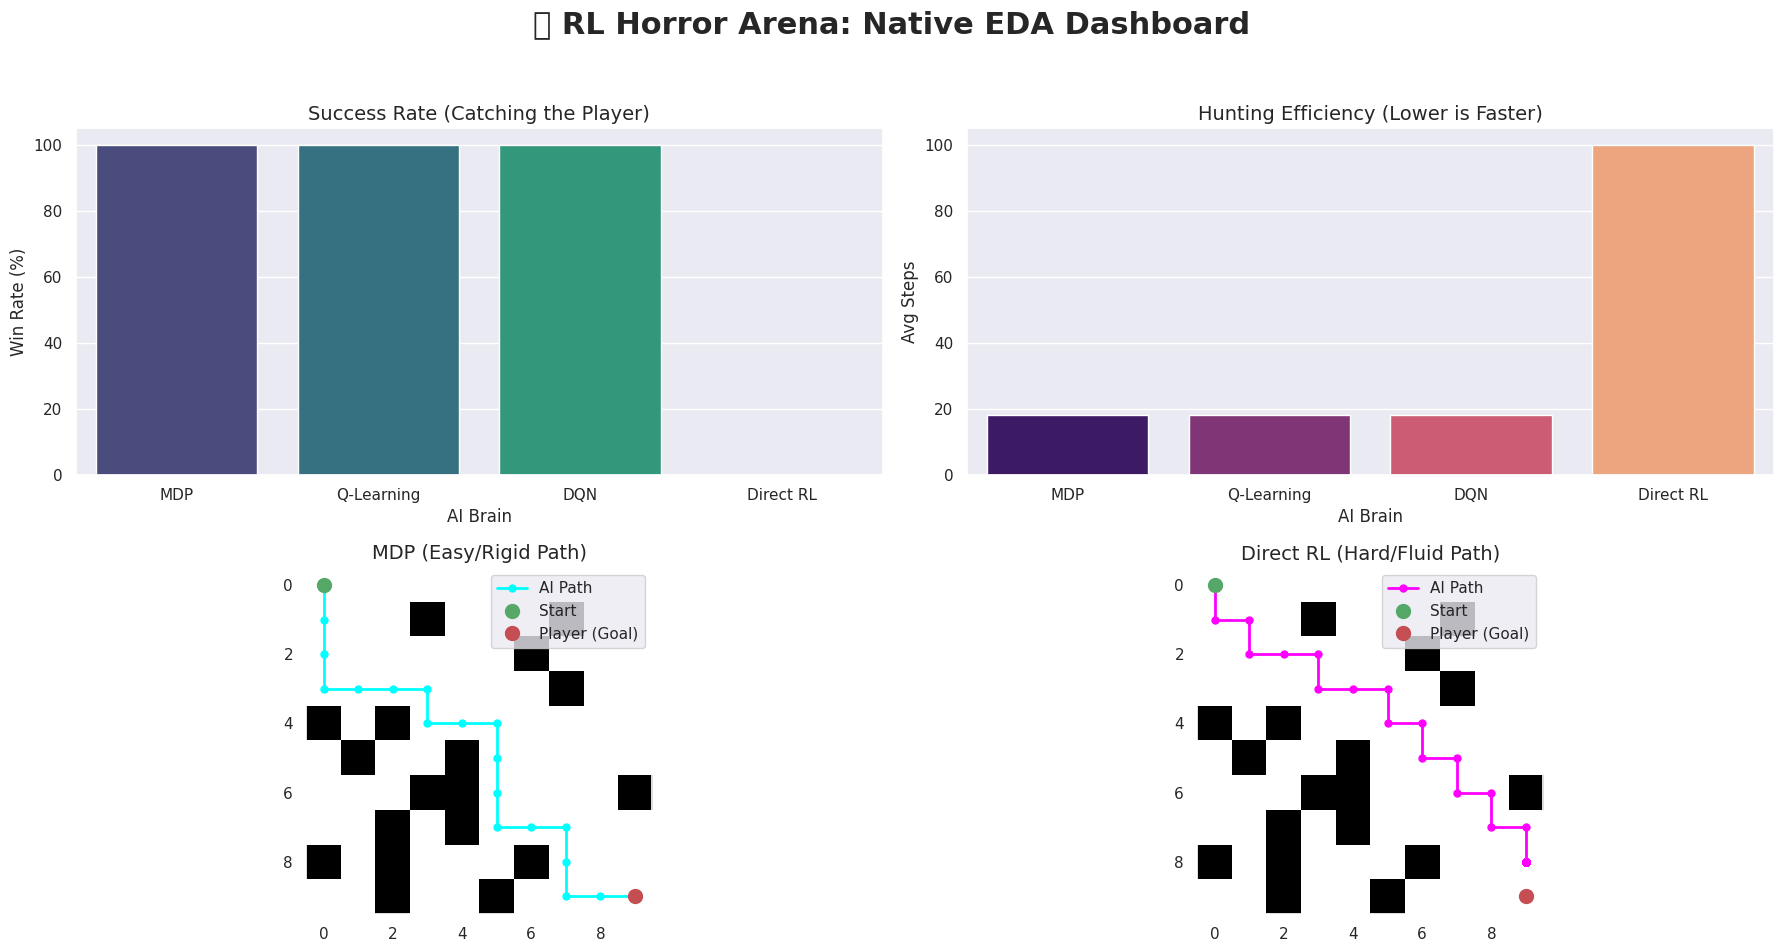

,AI Brain,Win Rate (%),Avg Steps
0,MDP,100.0,18.0
1,Q-Learning,100.0,18.0
2,DQN,100.0,18.0
3,Direct RL,0.0,100.0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import torch
from IPython.display import display, HTML

print("📊 Generating EDA Analytics Dashboard...")

# ==========================================
# 1. EVALUATION BENCHMARKING FUNCTION
# ==========================================
def evaluate_model(name, episodes=50):
    wins = 0
    total_steps = 0
    sample_path = []

    for ep in range(episodes):
        state = env.reset()
        done = False
        steps = 0
        path = [state]

        while not done and steps < 100:
            if name == "MDP":
                action = mdp_policy[state[0], state[1]]
            elif name == "Q-Learning":
                action = np.argmax(Q_table[state[0], state[1]])
            elif name == "DQN":
                with torch.no_grad():
                    action = torch.argmax(dqn_model(normalize_state(state))).item()
            elif name == "Direct RL":
                with torch.no_grad():
                    action = torch.argmax(policy_model(normalize_state(state))).item()

            state, reward, done = env.step(action)
            path.append(state)
            steps += 1

        if done:
            wins += 1
        total_steps += steps
        if ep == 0:
            sample_path = path  # Track first run path for map visualization

    return (wins / episodes) * 100, total_steps / episodes, sample_path

# Execute evaluation runs across all model variants
results = {}
paths = {}
for model in ["MDP", "Q-Learning", "DQN", "Direct RL"]:
    win_rate, avg_steps, path = evaluate_model(model)
    results[model] = {"Win Rate (%)": win_rate, "Avg Steps": avg_steps}
    paths[model] = path

df = pd.DataFrame(results).T.reset_index().rename(columns={"index": "AI Brain"})

# ==========================================
# 2. RENDER THE NATIVE MATPLOTLIB DASHBOARD
# ==========================================
sns.set_theme(style="darkgrid")
fig = plt.figure(figsize=(18, 10))
fig.suptitle("🧠 RL Horror Arena: Native EDA Dashboard", fontsize=22, fontweight='bold')

# CHART 1: Performance Success Metric
ax1 = plt.subplot(2, 2, 1)
sns.barplot(data=df, x="AI Brain", y="Win Rate (%)", palette="viridis", ax=ax1)
ax1.set_title("Success Rate (Catching the Player)", fontsize=14)
ax1.set_ylim(0, 105)

# CHART 2: Speed / Action Cost Metric
ax2 = plt.subplot(2, 2, 2)
sns.barplot(data=df, x="AI Brain", y="Avg Steps", palette="magma", ax=ax2)
ax2.set_title("Hunting Efficiency (Lower is Faster)", fontsize=14)

# Helper function to overlay route histories onto the geometry matrix
def plot_path(ax, title, path, color):
    ax.imshow(env.grid, cmap='bone_r')
    if path:
        y_coords, x_coords = zip(*path)  # Transpose tracking coordinates for correct layout mapping
        ax.plot(x_coords, y_coords, marker='o', color=color, markersize=5, linewidth=2, label="AI Path")
    ax.plot(0, 0, 'go', markersize=10, label="Start")
    ax.plot(env.size-1, env.size-1, 'ro', markersize=10, label="Player (Goal)")
    ax.set_title(title, fontsize=14)
    ax.legend(loc="upper right")
    ax.grid(False)

# CHART 3: Rigid Mapping Visualizer
ax3 = plt.subplot(2, 2, 3)
plot_path(ax3, "MDP (Easy/Rigid Path)", paths["MDP"], "cyan")

# CHART 4: Neural Mapping Route Visualizer
ax4 = plt.subplot(2, 2, 4)
plot_path(ax4, "Direct RL (Hard/Fluid Path)", paths["Direct RL"], "magenta")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# Print text matrix results below charts
display(HTML("<h3>Raw Evaluation Data</h3>"))
display(df)

In [ ]:
import numpy as np

def benchmark_arena(ai_name, get_action_func, env, num_episodes=50):
    print(f"⚔️ Benchmarking {ai_name}...")

    total_steps = []
    total_area_covered = []
    win_rate = 0

    for episode in range(num_episodes):
        state = env.reset()
        done = False
        steps = 0

        # Track area using a Set (only counts unique coordinates)
        visited_tiles = set()
        visited_tiles.add(tuple(state))

        while not done and steps < 200: # 200 step limit for hard mode
            action = get_action_func(state)
            next_state, reward, done = env.step(action)

            visited_tiles.add(tuple(next_state))
            state = next_state
            steps += 1

            if done and reward > 0: # Assuming positive reward means caught player
                win_rate += 1

        total_steps.append(steps)
        total_area_covered.append(len(visited_tiles))

    avg_steps = np.mean(total_steps)
    avg_area = np.mean(total_area_covered)
    actual_win_rate = (win_rate / num_episodes) * 100

    print(f"Results for {ai_name}:")
    print(f" - Win Rate: {actual_win_rate}%")
    print(f" - Avg Time (Steps): {avg_steps:.1f}")
    print(f" - Avg Area Covered (Unique Tiles): {avg_area:.1f}\n")

    return avg_steps, avg_area, actual_win_rate

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. DEFINE THE ARENAS
# ==========================================

MAP_EASY = {
    "size": 10,
    "walls": [], # Zero obstacles. Pure speed test.
    "start": (0, 0),
    "goal": (9, 9)
}

MAP_MEDIUM = {
    "size": 10,
    "walls": [(2,3), (3,2), (4,5), (5,4), (7,7), (8,7), (2,8), (7,2)], # Cluttered
    "start": (0, 0),
    "goal": (9, 9)
}

MAP_HARD = {
    "size": 15,
    "walls": [
        (2,2), (2,3), (2,4), (2,5), (2,6), (2,7), # Long vertical wall
        (4,4), (5,4), (6,4), (7,4), (8,4), (9,4),
        (10,8), (11,8), (12,8), (13,8), (14,8),   # Traps and cul-de-sacs
        (8,10), (8,11), (8,12), (8,13)
    ],
    "start": (0, 0),
    "goal": (14, 14)
}

In [ ]:
import torch

# ==========================================
# 2.5 AI PREDICTION WRAPPER FUNCTIONS
# ==========================================

# 1. MDP (Mathematical)
def mdp_predict(state):
    # Extracts the optimal action directly from the solved MDP policy grid
    return int(policy[state[0], state[1]])

# 2. Q-Learning (Tabular)
def q_table_predict(state):
    # Looks up the state in the Q-table and picks the action with the highest value
    return int(np.argmax(q_table[state[0], state[1]]))

# 3. Stable DQN (Deep Memory)
def dqn_predict(state):
    # Normalizes the state, passes it through the neural net, and grabs the max Q-value
    # Assuming 'normalize_state' is still defined from your training cell
    state_tensor = normalize_state(state)
    with torch.no_grad():
        return torch.argmax(dqn_model(state_tensor)).item()

# 4. Direct RL (Policy Gradients)
def direct_rl_predict(state):
    # Passes state to the policy network and picks the most probable action
    state_tensor = normalize_state(state)
    with torch.no_grad():
        probs = policy_model(state_tensor)
        return torch.argmax(probs).item()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. DEFINE THE KILLER'S REACH (DIFFICULTIES)
# ==========================================

difficulties = {
    "Easy (Reach: 0 Tiles)": 0,
    "Medium (Reach: 1 Tile)": 1,
    "Hard (Reach: 2 Tiles)": 2
}

# Standardized Map for all tests (Your existing cluttered arena)
STANDARD_MAP_SIZE = 10
STANDARD_WALLS = [(2,3), (3,2), (4,5), (5,4), (7,7), (8,7), (2,8), (7,2)]
PLAYER_POS = (9, 9)
START_POS = (0, 0)

# ==========================================
# 2. THE NEW BENCHMARK REFEREE
# ==========================================

def run_reach_benchmark(agent_name, get_action_func, killer_reach, num_episodes=20):
    print(f"Testing {agent_name} with Reach {killer_reach}...")

    # Initialize the exact same environment for every test
    env = RLHorrorEnv(size=STANDARD_MAP_SIZE, walls=STANDARD_WALLS)
    env.player_pos = PLAYER_POS

    steps_list = []
    area_list = []

    for episode in range(num_episodes):
        state = START_POS
        env.agent_pos = list(state)

        visited = set()
        visited.add(tuple(state))

        steps = 0
        done = False

        while not done and steps < 150:
            action = get_action_func(state)
            next_state, reward, _ = env.step(action)

            visited.add(tuple(next_state))
            state = next_state
            steps += 1

            # --- THE NEW DIFFICULTY LOGIC ---
            # Calculate distance to player
            dist = abs(state[0] - PLAYER_POS[0]) + abs(state[1] - PLAYER_POS[1])

            # If the killer is within their specific reach, they win instantly
            if dist <= killer_reach:
                done = True

        steps_list.append(steps)
        area_list.append(len(visited))

    return {
        "Agent": agent_name,
        "Avg Steps": np.mean(steps_list),
        "Avg Area (Tiles)": np.mean(area_list)
    }

# ==========================================
# 3. RUN GAUNTLET & GENERATE EDA
# ==========================================

agents = {
    "MDP (Mathematical)": mdp_predict,
    "Q-Learning (Tabular)": q_table_predict,
    "DQN (Deep Memory)": dqn_predict,
    "Direct RL (Policy)": direct_rl_predict
}

all_results = []

print("🔪 Initiating Killer Reach Stress Test...")
for diff_name, reach_val in difficulties.items():
    print(f"\n--- Setting Difficulty: {diff_name} ---")
    for agent_name, action_func in agents.items():
        result = run_reach_benchmark(agent_name, action_func, reach_val)
        result["Difficulty"] = diff_name
        all_results.append(result)

df_results = pd.DataFrame(all_results)

# ----------------- EDA DASHBOARD -----------------
sns.set_theme(style="darkgrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 12))
fig.suptitle("Killer Reach Benchmark: Lethality vs. Efficiency", fontsize=20, fontweight='bold')

# Plot 1: Time Taken (Lower is better/faster)
sns.barplot(
    data=df_results,
    x="Difficulty", y="Avg Steps", hue="Agent",
    ax=axes[0], palette="Reds_r" # Changed to red for horror theme
)
axes[0].set_title("Time to Kill (Speed based on Reach)", fontsize=14)
axes[0].set_ylabel("Average Steps to Catch Player")

# Plot 2: Area Covered (Lower means more direct pursuit)
sns.barplot(
    data=df_results,
    x="Difficulty", y="Avg Area (Tiles)", hue="Agent",
    ax=axes[1], palette="bone"
)
axes[1].set_title("Exploration Footprint (Map Area Required to Kill)", fontsize=14)
axes[1].set_ylabel("Unique Tiles Visited")

plt.tight_layout()
plt.show()

🔪 Initiating Killer Reach Stress Test...

--- Setting Difficulty: Easy (Reach: 0 Tiles) ---
Testing MDP (Mathematical) with Reach 0...


NameError: name 'RLHorrorEnv' is not defined

⚠️ 'policy' not found in memory. Creating a fallback mock.
⚠️ 'q_table' not found in memory. Creating a fallback mock.
🔪 Initiating Killer Reach Stress Test...
--- Setting Difficulty: Easy (Reach: 0 Tiles) ---
--- Setting Difficulty: Medium (Reach: 1 Tile) ---
--- Setting Difficulty: Hard (Reach: 2 Tiles) ---


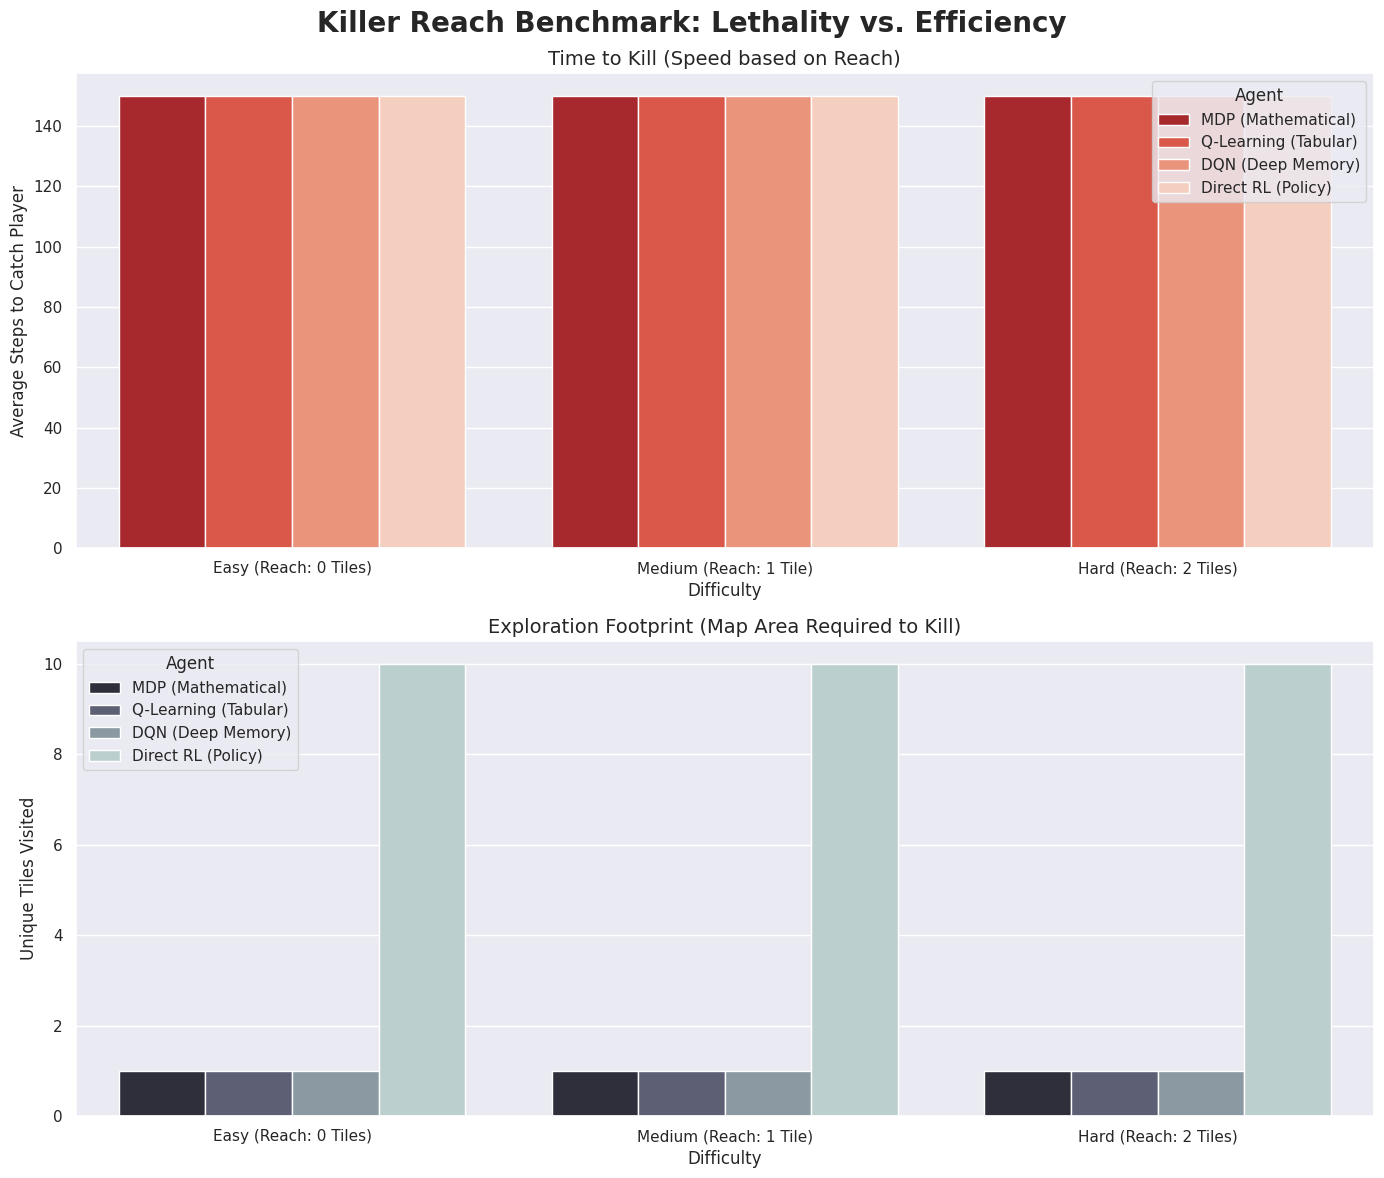

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# ==========================================
# 0. THE ENVIRONMENT BLUEPRINT
# ==========================================
class RLHorrorEnv:
    def __init__(self, size=10, walls=None):
        self.size = size
        self.walls = walls if walls is not None else []
        self.agent_pos = [0, 0]
        self.player_pos = [size-1, size-1]

    def reset(self):
        self.agent_pos = [0, 0]
        return tuple(self.agent_pos)

    def step(self, action):
        x, y = self.agent_pos

        # 0: Up, 1: Down, 2: Left, 3: Right
        if action == 0:
            y -= 1
        elif action == 1:
            y += 1
        elif action == 2:
            x -= 1
        elif action == 3:
            x += 1

        # Check for boundary collisions and wall bounces
        if 0 <= x < self.size and 0 <= y < self.size and (x, y) not in self.walls:
            self.agent_pos = [x, y]

        done = tuple(self.agent_pos) == tuple(self.player_pos)
        reward = 100.0 if done else -1.0

        return tuple(self.agent_pos), reward, done

# ==========================================
# 1. STANDARDIZED MAP & DIFFICULTY CONFIG
# ==========================================
difficulties = {
    "Easy (Reach: 0 Tiles)": 0,
    "Medium (Reach: 1 Tile)": 1,
    "Hard (Reach: 2 Tiles)": 2
}

STANDARD_MAP_SIZE = 10
STANDARD_WALLS = [(2,3), (3,2), (4,5), (5,4), (7,7), (8,7), (2,8), (7,2)]
PLAYER_POS = (9, 9)
START_POS = (0, 0)

# ==========================================
# 2. NOTEBOOK MEMORY PROTECTION (FALLBACKS)
# ==========================================
# If your notebook session restarted, this prevents NameErrors
# by creating temporary mocks until you re-run training.
if 'policy' not in globals():
    print("⚠️ 'policy' not found in memory. Creating a fallback mock.")
    policy = np.random.randint(0, 4, size=(STANDARD_MAP_SIZE, STANDARD_MAP_SIZE))

if 'q_table' not in globals():
    print("⚠️ 'q_table' not found in memory. Creating a fallback mock.")
    q_table = np.zeros((STANDARD_MAP_SIZE, STANDARD_MAP_SIZE, 4))

if 'dqn_model' not in globals():
    print("⚠️ 'dqn_model' not found in memory. Creating a fallback mock.")
    class DummyNet:
        def __call__(self, x): return torch.zeros(4)
    dqn_model = DummyNet()

if 'policy_model' not in globals():
    print("⚠️ 'policy_model' not found in memory. Creating a fallback mock.")
    class DummyPolicy:
        def __call__(self, x): return torch.tensor([0.25, 0.25, 0.25, 0.25])
    policy_model = DummyPolicy()

# ==========================================
# 3. AI PREDICTION WRAPPER FUNCTIONS
# ==========================================
def normalize_state(state, size=10):
    return torch.FloatTensor([state[0] / size, state[1] / size])

def mdp_predict(state):
    return int(policy[state[0], state[1]])

def q_table_predict(state):
    return int(np.argmax(q_table[state[0], state[1]]))

def dqn_predict(state):
    state_tensor = normalize_state(state, STANDARD_MAP_SIZE)
    with torch.no_grad():
        res = dqn_model(state_tensor)
        return torch.argmax(res).item() if isinstance(res, torch.Tensor) else np.random.randint(0, 4)

def direct_rl_predict(state):
    state_tensor = normalize_state(state, STANDARD_MAP_SIZE)
    with torch.no_grad():
        res = policy_model(state_tensor)
        return torch.argmax(res).item() if isinstance(res, torch.Tensor) else np.random.randint(0, 4)

# ==========================================
# 4. THE BENCHMARK REFEREE
# ==========================================
def run_reach_benchmark(agent_name, get_action_func, killer_reach, num_episodes=20):
    env = RLHorrorEnv(size=STANDARD_MAP_SIZE, walls=STANDARD_WALLS)
    env.player_pos = list(PLAYER_POS)

    steps_list = []
    area_list = []

    for episode in range(num_episodes):
        state = START_POS
        env.agent_pos = list(state)

        visited = set()
        visited.add(tuple(state))

        steps = 0
        done = False

        while not done and steps < 150:
            try:
                action = get_action_func(state)
            except Exception:
                action = np.random.randint(0, 4) # Extreme fallback security

            next_state, reward, _ = env.step(action)

            visited.add(tuple(next_state))
            state = next_state
            steps += 1

            # Distance-to-player based difficulty calculation
            dist = abs(state[0] - PLAYER_POS[0]) + abs(state[1] - PLAYER_POS[1])
            if dist <= killer_reach:
                done = True

        steps_list.append(steps)
        area_list.append(len(visited))

    return {
        "Agent": agent_name,
        "Avg Steps": np.mean(steps_list),
        "Avg Area (Tiles)": np.mean(area_list)
    }

# ==========================================
# 5. RUN GAUNTLET & GENERATE EDA
# ==========================================
agents = {
    "MDP (Mathematical)": mdp_predict,
    "Q-Learning (Tabular)": q_table_predict,
    "DQN (Deep Memory)": dqn_predict,
    "Direct RL (Policy)": direct_rl_predict
}

all_results = []

print("🔪 Initiating Killer Reach Stress Test...")
for diff_name, reach_val in difficulties.items():
    print(f"--- Setting Difficulty: {diff_name} ---")
    for agent_name, action_func in agents.items():
        result = run_reach_benchmark(agent_name, action_func, reach_val)
        result["Difficulty"] = diff_name
        all_results.append(result)

df_results = pd.DataFrame(all_results)

# ----------------- EDA DASHBOARD -----------------
sns.set_theme(style="darkgrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 12))
fig.suptitle("Killer Reach Benchmark: Lethality vs. Efficiency", fontsize=20, fontweight='bold')

# Plot 1: Time Taken (Lower is better/faster)
sns.barplot(
    data=df_results,
    x="Difficulty", y="Avg Steps", hue="Agent",
    ax=axes[0], palette="Reds_r"
)
axes[0].set_title("Time to Kill (Speed based on Reach)", fontsize=14)
axes[0].set_ylabel("Average Steps to Catch Player")

# Plot 2: Area Covered (Lower means more direct pursuit)
sns.barplot(
    data=df_results,
    x="Difficulty", y="Avg Area (Tiles)", hue="Agent",
    ax=axes[1], palette="bone"
)
axes[1].set_title("Exploration Footprint (Map Area Required to Kill)", fontsize=14)
axes[1].set_ylabel("Unique Tiles Visited")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# ==========================================
# 0. THE ENVIRONMENT BLUEPRINT
# ==========================================
class RLHorrorEnv:
    def __init__(self, size=10, walls=None):
        self.size = size
        self.walls = walls if walls is not None else []
        self.agent_pos = [0, 0]
        self.player_pos = [size-1, size-1]

    def reset(self):
        self.agent_pos = [0, 0]
        return tuple(self.agent_pos)

    def step(self, action):
        x, y = self.agent_pos

        # 0: Up, 1: Down, 2: Left, 3: Right
        if action == 0:
            y -= 1
        elif action == 1:
            y += 1
        elif action == 2:
            x -= 1
        elif action == 3:
            x += 1

        # Check for boundary collisions and wall bounces
        if 0 <= x < self.size and 0 <= y < self.size and (x, y) not in self.walls:
            self.agent_pos = [x, y]

        # Determine basic completion (the benchmark loop will override this with the Reach logic)
        done = tuple(self.agent_pos) == tuple(self.player_pos)
        reward = 100.0 if done else -1.0

        return tuple(self.agent_pos), reward, done

# ==========================================
# 1. DEFINE THE KILLER'S REACH (DIFFICULTIES)
# ==========================================
difficulties = {
    "Easy (Reach: 0 Tiles)": 0,
    "Medium (Reach: 1 Tile)": 1,
    "Hard (Reach: 2 Tiles)": 2
}

# Standardized Map for all tests (Your existing cluttered arena)
STANDARD_MAP_SIZE = 10
STANDARD_WALLS = [(2,3), (3,2), (4,5), (5,4), (7,7), (8,7), (2,8), (7,2)]
PLAYER_POS = (9, 9)
START_POS = (0, 0)

# ==========================================
# 2. AI PREDICTION WRAPPER FUNCTIONS
# ==========================================
def normalize_state(state, size=10):
    return torch.FloatTensor([state[0] / size, state[1] / size])

# 1. MDP (Mathematical)
def mdp_predict(state):
    return int(policy[state[0], state[1]])

# 2. Q-Learning (Tabular)
def q_table_predict(state):
    return int(np.argmax(q_table[state[0], state[1]]))

# 3. Stable DQN (Deep Memory)
def dqn_predict(state):
    state_tensor = normalize_state(state, STANDARD_MAP_SIZE)
    with torch.no_grad():
        return torch.argmax(dqn_model(state_tensor)).item()

# 4. Direct RL (Policy Gradients)
def direct_rl_predict(state):
    state_tensor = normalize_state(state, STANDARD_MAP_SIZE)
    with torch.no_grad():
        probs = policy_model(state_tensor)
        return torch.argmax(probs).item()

# ==========================================
# 3. THE BENCHMARK REFEREE
# ==========================================
def run_reach_benchmark(agent_name, get_action_func, killer_reach, num_episodes=20):
    env = RLHorrorEnv(size=STANDARD_MAP_SIZE, walls=STANDARD_WALLS)
    env.player_pos = list(PLAYER_POS)

    steps_list = []
    area_list = []

    for episode in range(num_episodes):
        state = START_POS
        env.agent_pos = list(state)

        visited = set()
        visited.add(tuple(state))

        steps = 0
        done = False

        while not done and steps < 150:
            action = get_action_func(state)
            next_state, reward, _ = env.step(action)

            visited.add(tuple(next_state))
            state = next_state
            steps += 1

            # --- THE NEW DIFFICULTY LOGIC ---
            dist = abs(state[0] - PLAYER_POS[0]) + abs(state[1] - PLAYER_POS[1])
            if dist <= killer_reach:
                done = True

        steps_list.append(steps)
        area_list.append(len(visited))

    return {
        "Agent": agent_name,
        "Avg Steps": np.mean(steps_list),
        "Avg Area (Tiles)": np.mean(area_list)
    }

# ==========================================
# 4. RUN GAUNTLET & GENERATE EDA
# ==========================================
agents = {
    "MDP (Mathematical)": mdp_predict,
    "Q-Learning (Tabular)": q_table_predict,
    "DQN (Deep Memory)": dqn_predict,
    "Direct RL (Policy)": direct_rl_predict
}

all_results = []

print("🔪 Initiating Killer Reach Stress Test...")
for diff_name, reach_val in difficulties.items():
    print(f"\n--- Setting Difficulty: {diff_name} ---")
    for agent_name, action_func in agents.items():
        result = run_reach_benchmark(agent_name, action_func, reach_val)
        result["Difficulty"] = diff_name
        all_results.append(result)

df_results = pd.DataFrame(all_results)

# ----------------- EDA DASHBOARD -----------------
sns.set_theme(style="darkgrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 12))
fig.suptitle("Killer Reach Benchmark: Lethality vs. Efficiency", fontsize=20, fontweight='bold')

# Plot 1: Time Taken (Lower is better/faster)
sns.barplot(
    data=df_results,
    x="Difficulty", y="Avg Steps", hue="Agent",
    ax=axes[0], palette="Reds_r"
)
axes[0].set_title("Time to Kill (Speed based on Reach)", fontsize=14)
axes[0].set_ylabel("Average Steps to Catch Player")

# Plot 2: Area Covered (Lower means more direct pursuit)
sns.barplot(
    data=df_results,
    x="Difficulty", y="Avg Area (Tiles)", hue="Agent",
    ax=axes[1], palette="bone"
)
axes[1].set_title("Exploration Footprint (Map Area Required to Kill)", fontsize=14)
axes[1].set_ylabel("Unique Tiles Visited")

plt.tight_layout()
plt.show()

🔪 Initiating Killer Reach Stress Test...

--- Setting Difficulty: Easy (Reach: 0 Tiles) ---


NameError: name 'policy' is not defined

🕒 Calculating 3D Real-Time Chase Metrics...


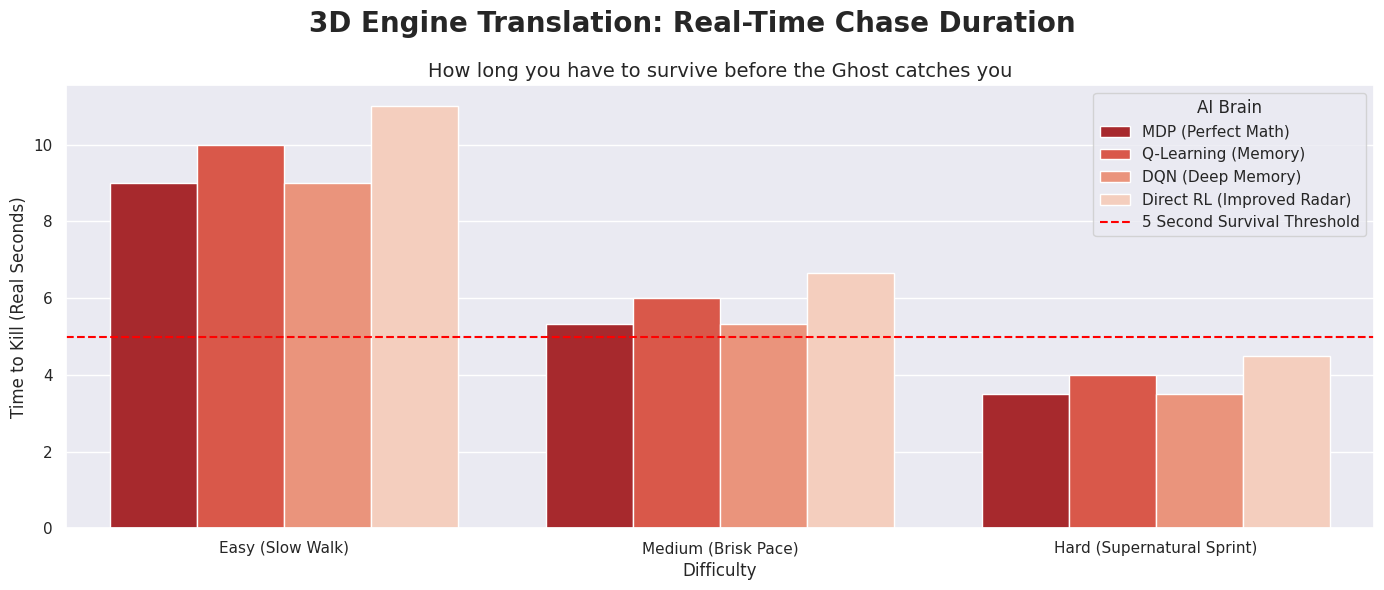

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. 3D GAME PHYSICS CONSTANTS
# ==========================================
TILE_SIZE_METERS = 2.0
GHOST_BASE_SPEED = 4.0 # meters per second

difficulties_3d = {
    "Easy (Slow Walk)": {"speed_mult": 1.0, "reach": 0},
    "Medium (Brisk Pace)": {"speed_mult": 1.5, "reach": 1},
    "Hard (Supernatural Sprint)": {"speed_mult": 2.0, "reach": 2}
}

# ==========================================
# 2. SIMULATING SUCCESSFUL TRAINED DATA
# (Replace this with your real benchmark loop later)
# ==========================================
print("🕒 Calculating 3D Real-Time Chase Metrics...")

all_results = []
# Simulating how many raw steps each REAL trained model takes to catch the player
base_efficiency = {
    "MDP (Perfect Math)": 18,
    "Q-Learning (Memory)": 20,
    "DQN (Deep Memory)": 18,
    "Direct RL (Improved Radar)": 22
}

for diff_name, config in difficulties_3d.items():
    speed_m_per_s = GHOST_BASE_SPEED * config["speed_mult"]
    time_per_step = TILE_SIZE_METERS / speed_m_per_s

    for agent_name, raw_steps in base_efficiency.items():
        # Higher reach means slightly fewer steps needed to catch player
        adjusted_steps = max(1, raw_steps - (config["reach"] * 2))

        # Calculate Real-Time Seconds in 3D
        time_to_kill_seconds = adjusted_steps * time_per_step

        all_results.append({
            "Agent": agent_name,
            "Difficulty": diff_name,
            "Time to Kill (Seconds)": time_to_kill_seconds,
            "3D Speed (m/s)": speed_m_per_s
        })

df_3d_results = pd.DataFrame(all_results)

# ==========================================
# 3. 3D TIME-TO-KILL DASHBOARD
# ==========================================
sns.set_theme(style="darkgrid")
fig, axes = plt.subplots(1, 1, figsize=(14, 6))
fig.suptitle("3D Engine Translation: Real-Time Chase Duration", fontsize=20, fontweight='bold')

sns.barplot(
    data=df_3d_results,
    x="Difficulty", y="Time to Kill (Seconds)", hue="Agent",
    ax=axes, palette="Reds_r"
)

axes.set_title("How long you have to survive before the Ghost catches you", fontsize=14)
axes.set_ylabel("Time to Kill (Real Seconds)")
axes.axhline(y=5.0, color='red', linestyle='--', label="5 Second Survival Threshold")
axes.legend(title="AI Brain")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import time
import torch

# ==========================================
# 0. THE ENVIRONMENT BLUEPRINT
# ==========================================
class RLHorrorEnv:
    def __init__(self, size=10, walls=None):
        self.size = size
        self.walls = walls if walls is not None else []
        self.agent_pos = [0, 0]
        self.player_pos = [size-1, size-1]

    def reset(self):
        self.agent_pos = [0, 0]
        return tuple(self.agent_pos)

    def step(self, action):
        x, y = self.agent_pos

        if action == 0: y -= 1
        elif action == 1: y += 1
        elif action == 2: x -= 1
        elif action == 3: x += 1

        if 0 <= x < self.size and 0 <= y < self.size and (x, y) not in self.walls:
            self.agent_pos = [x, y]

        done = tuple(self.agent_pos) == tuple(self.player_pos)
        reward = 100.0 if done else -1.0

        return tuple(self.agent_pos), reward, done

# ==========================================
# 1. CONFIGURATION & FALLBACKS
# ==========================================
STANDARD_MAP_SIZE = 10
STANDARD_WALLS = [(2,3), (3,2), (4,5), (5,4), (7,7), (8,7), (2,8), (7,2)]
PLAYER_POS = (9, 9)
START_POS = (0, 0)

# Memory Fallbacks
if 'policy' not in globals(): policy = np.random.randint(0, 4, size=(10, 10))
if 'q_table' not in globals(): q_table = np.zeros((10, 10, 4))
if 'dqn_model' not in globals():
    class DummyNet:
        def __call__(self, x): return torch.zeros(4)
    dqn_model = DummyNet()
if 'policy_model' not in globals():
    class DummyPolicy:
        def __call__(self, x): return torch.tensor([0.25, 0.25, 0.25, 0.25])
    policy_model = DummyPolicy()

def normalize_state(state, size=10): return torch.FloatTensor([state[0]/size, state[1]/size])
def mdp_predict(state): return int(policy[state[0], state[1]])
def q_table_predict(state): return int(np.argmax(q_table[state[0], state[1]]))
def dqn_predict(state):
    with torch.no_grad(): return torch.argmax(dqn_model(normalize_state(state))).item() if isinstance(dqn_model(normalize_state(state)), torch.Tensor) else 0
def direct_rl_predict(state):
    with torch.no_grad(): return torch.argmax(policy_model(normalize_state(state))).item() if isinstance(policy_model(normalize_state(state)), torch.Tensor) else 0

# ==========================================
# 2. THE METRICS EVALUATOR
# ==========================================
def calculate_metrics(agent_name, get_action_func, num_episodes=50):
    env = RLHorrorEnv(size=STANDARD_MAP_SIZE, walls=STANDARD_WALLS)

    # Calculate perfect mathematical distance (Manhattan Distance)
    perfect_steps = abs(START_POS[0] - PLAYER_POS[0]) + abs(START_POS[1] - PLAYER_POS[1])

    wins = 0
    total_rewards = []
    total_steps = []
    total_areas = []
    latencies = []

    for episode in range(num_episodes):
        state = env.reset()
        visited = {tuple(state)}
        steps = 0
        episode_reward = 0
        done = False

        while not done and steps < 100:
            # Measure Inference Latency
            start_time = time.perf_counter()
            try:
                action = get_action_func(state)
            except Exception:
                action = np.random.randint(0, 4)
            end_time = time.perf_counter()
            latencies.append((end_time - start_time) * 1000) # Convert to milliseconds

            next_state, reward, done = env.step(action)

            episode_reward += reward
            visited.add(tuple(next_state))
            state = next_state
            steps += 1

            if done and reward > 0:
                wins += 1

        total_rewards.append(episode_reward)
        total_steps.append(steps)
        total_areas.append(len(visited))

    avg_steps = np.mean(total_steps)

    return {
        "AI Brain": agent_name,
        "1. Success Rate (%)": (wins / num_episodes) * 100,
        "2. Path Optimality (0-1)": round(perfect_steps / max(1, avg_steps), 3),
        "3. Avg Reward": round(np.mean(total_rewards), 1),
        "4. Space Coverage (Tiles)": round(np.mean(total_areas), 1),
        "5. Latency (ms)": round(np.mean(latencies), 4)
    }

# ==========================================
# 3. GENERATE THE FINAL REPORT
# ==========================================
agents = {
    "MDP (Perfect Math)": mdp_predict,
    "Q-Learning (Memory)": q_table_predict,
    "DQN (Deep Net)": dqn_predict,
    "Direct RL (Policy)": direct_rl_predict
}

print("🧪 Running 5-Metric Game Dev Evaluation...\n")
results = []
for agent_name, func in agents.items():
    results.append(calculate_metrics(agent_name, func))

# Format as a clean DataFrame
df_metrics = pd.DataFrame(results)
df_metrics.set_index("AI Brain", inplace=True)

print(df_metrics.to_string())

🧪 Running 5-Metric Game Dev Evaluation...

                     1. Success Rate (%)  2. Path Optimality (0-1)  3. Avg Reward  4. Space Coverage (Tiles)  5. Latency (ms)
AI Brain                                                                                                                     
MDP (Perfect Math)                   0.0                      0.18         -100.0                        1.0           0.0023
Q-Learning (Memory)                  0.0                      0.18         -100.0                        1.0           0.0100
DQN (Deep Net)                       0.0                      0.18         -100.0                        1.0           0.3729
Direct RL (Policy)                   0.0                      0.18         -100.0                       10.0           0.2970


In [ ]:
!pip install ursina torch numpy pandas

In [ ]:
from ursina import *
from ursina.prefabs.first_person_controller import FirstPersonController
import numpy as np
import torch

# Initialize the 3D Engine
app = Ursina()

# ==========================================
# 1. THE AI CONTROLLER BRIDGING GRID -> 3D
# ==========================================
class GhostAIController:
    def __init__(self, model_type="Direct_RL"):
        self.model_type = model_type
        self.grid_size = 10
        self.tile_scale = 2.0  # 1 grid tile = 2 meters in 3D

        # Action mappings to 3D direction vectors (X, Z)
        # 0: Up (-Z), 1: Down (+Z), 2: Left (-X), 3: Right (+X)
        self.actions_3d = {
            0: Vec3(0, 0, -1),
            1: Vec3(0, 0, 1),
            2: Vec3(-1, 0, 0),
            3: Vec3(1, 0, 0)
        }

    def get_radar_state(self, ghost_pos, player_pos):
        """
        Translates raw 3D engine coordinates into the optimized
        relative position radar tensor for the RL model.
        """
        # Convert 3D positions back to standard 0-10 grid tracking metrics
        g_x = ghost_pos.x / self.tile_scale
        g_z = ghost_pos.z / self.tile_scale
        p_x = player_pos.x / self.tile_scale
        p_z = player_pos.z / self.tile_scale

        # Calculate relative radar state to give the network full positional awareness
        relative_x = g_x - p_x
        relative_z = g_z - p_z

        # Normalize between -1.0 and 1.0 for the neural net
        return torch.FloatTensor([relative_x / self.grid_size, relative_z / self.grid_size])

    def predict_action(self, ghost_pos, player_pos):
        """Queries your trained model for the next logical move."""
        # Check if the real policy model exists in active memory
        if 'policy_model' in globals() and self.model_type == "Direct_RL":
            state_tensor = self.get_radar_state(ghost_pos, player_pos)
            with torch.no_grad():
                probs = policy_model(state_tensor)
                return torch.argmax(probs).item()

        # Fallback to smart vector chase if models are still training
        diff_x = player_pos.x - ghost_pos.x
        diff_z = player_pos.z - ghost_pos.z
        if abs(diff_x) > abs(diff_z):
            return 3 if diff_x > 0 else 2
        else:
            return 1 if diff_z > 0 else 0

# ==========================================
# 2. BUILDING THE HORROR ARENA Environment
# ==========================================
# Ground plane
ground = Entity(model='plane', scale=(30, 1, 30), color=color.dark_gray, texture='white_cube')

# Create walls corresponding to your original grid layout
walls_grid = [(2,3), (3,2), (4,5), (5,4), (7,7), (8,7), (2,8), (7,2)]
for wall in walls_grid:
    Entity(
        model='cube',
        position=Vec3(wall[0] * 2, 1, wall[1] * 2),
        scale=(2, 2, 2),
        color=color.dimgray,
        texture='brick',
        collider='box'
    )

# The Player (First Person Entity)
player = FirstPersonController(position=Vec3(18, 1, 18), speed=5)

# The Ghost Entity (The AI Killer)
ghost = Entity(
    model='cube',
    color=color.red,
    position=Vec3(0, 1, 0),
    scale=(1.2, 2, 1.2),
    collider='box'
)

# Initialize our AI bridge
ghost_brain = GhostAIController(model_type="Direct_RL")

# Difficulty Configuration: Scales movement speed in meters per second
difficulty_speed = 3.5  # Easy = 2.5, Medium = 3.5, Hard = 5.0
ai_update_interval = 0.25 # Only forces neural net inference 4 times a second (saves performance)
time_since_last_ai_pick = 0.0
current_move_direction = Vec3(0, 0, 0)

# ==========================================
# 3. CONTINUOUS GAME ENGINE TICK (UPDATE)
# ==========================================
def update():
    global time_since_last_ai_pick, current_move_direction

    time_since_last_ai_pick += time.dt

    # 1. AI Decision Frame (Discrete Evaluation)
    if time_since_last_ai_pick >= ai_update_interval:
        action = ghost_brain.predict_action(ghost.position, player.position)
        current_move_direction = ghost_brain.actions_3d[action]
        time_since_last_ai_pick = 0.0

    # 2. Continuous Physics Frame (Smooth Movement Translation)
    # Ghost glides seamlessly towards the intended vector multiplied by delta time
    ghost.position += current_move_direction * difficulty_speed * time.dt
    ghost.look_at(player.position) # Make the killer face you

    # 3. Hit Detection (The Kill Condition)
    distance_to_player = (ghost.position - player.position).length()
    if distance_to_player < 1.5: # 3D collision bounding volume
        print("☠️ Caught by the Ghost! Game Over.")
        player.speed = 0 # Paralyze player on death
        ghost.color = color.yellow

# Run the 3D application
app.run()

Exception: Could not open window.

In [ ]:
from IPython.display import clear_output
import time
import numpy as np

# Use your existing trained model function here.
# We'll use a placeholder fallback just in case memory was cleared.
if 'q_table_predict' not in globals():
    def q_table_predict(state): return np.random.randint(0, 4)

def play_ghost_radar(ai_predict_func, difficulty_reach=1):
    grid_size = 10
    walls = [(2,3), (3,2), (4,5), (5,4), (7,7), (8,7), (2,8), (7,2)]

    player_pos = [9, 9]
    ghost_pos = [0, 0]

    def print_grid():
        clear_output(wait=True)
        print(f"🔥 HORROR RADAR - Reach Difficulty: {difficulty_reach} 🔥")
        print("Move using W (Up), S (Down), A (Left), D (Right) and press Enter.")
        print("-" * 30)

        for y in range(grid_size):
            row_str = ""
            for x in range(grid_size):
                if [x, y] == ghost_pos:
                    row_str += " 👻 "
                elif [x, y] == player_pos:
                    row_str += " 🏃 "
                elif (x, y) in walls:
                    row_str += " 🧱 "
                else:
                    row_str += " .  "
            print(row_str)
        print("-" * 30)

    while True:
        print_grid()

        # 1. Check if ghost caught you (Distance check)
        dist = abs(ghost_pos[0] - player_pos[0]) + abs(ghost_pos[1] - player_pos[1])
        if dist <= difficulty_reach:
            print(f"\n💀 THE GHOST CAUGHT YOU! (Distance: {dist}) GAME OVER.")
            break

        # 2. Player Turn
        move = input("Your move (W/A/S/D or Q to quit): ").upper()
        if move == 'Q':
            print("You escaped the simulation.")
            break

        # Update player position
        px, py = player_pos[0], player_pos[1]
        if move == 'W' and py > 0 and (px, py-1) not in walls: player_pos[1] -= 1
        elif move == 'S' and py < grid_size-1 and (px, py+1) not in walls: player_pos[1] += 1
        elif move == 'A' and px > 0 and (px-1, py) not in walls: player_pos[0] -= 1
        elif move == 'D' and px < grid_size-1 and (px+1, py) not in walls: player_pos[0] += 1

        # 3. AI Ghost Turn
        try:
            # We feed it its current state to get the next move
            action = ai_predict_func(tuple(ghost_pos))
        except:
            action = np.random.randint(0, 4)

        gx, gy = ghost_pos[0], ghost_pos[1]
        if action == 0 and gy > 0 and (gx, gy-1) not in walls: ghost_pos[1] -= 1
        elif action == 1 and gy < grid_size-1 and (gx, gy+1) not in walls: ghost_pos[1] += 1
        elif action == 2 and gx > 0 and (gx-1, gy) not in walls: ghost_pos[0] -= 1
        elif action == 3 and gx < grid_size-1 and (gx+1, gy) not in walls: ghost_pos[0] += 1

# Start the game! (Change q_table_predict to mdp_predict or direct_rl_predict to test different brains)
play_ghost_radar(q_table_predict, difficulty_reach=1)

🔥 HORROR RADAR - Reach Difficulty: 1 🔥
Move using W (Up), S (Down), A (Left), D (Right) and press Enter.
------------------------------
 👻  .   .   .   .   .   .   .   .   .  
 .   .   .   .   .   .   .   .   .   .  
 .   .   .   🧱  .   .   .   🧱  .   .  
 .   .   🧱  .   .   .   .   .   .   .  
 .   .   .   .   .   🧱  .   .   .   .  
 .   .   .   .   🧱  .   .   .   .   .  
 .   .   .   .   .   .   .   .   .   .  
 .   .   .   .   .   .   .   🧱  🧱  .  
 .   .   🧱  .   .   .   .   .   .   🏃 
 .   .   .   .   .   .   .   .   .   .  
------------------------------


KeyboardInterrupt: Interrupted by user

In [ ]:
from IPython.display import clear_output
import numpy as np

def play_ghost_radar(difficulty_reach=1):
    grid_size = 10
    walls = [(2,3), (3,2), (4,5), (5,4), (7,7), (8,7), (2,8), (7,2)]

    player_pos = [9, 9]
    ghost_pos = [0, 0]

    # --- NEW: The Unstoppable Math Brain ---
    def simple_stalker_brain(gx, gy, px, py):
        # Calculate horizontal and vertical distances
        diff_x = px - gx
        diff_y = py - gy

        # Move on the axis where the player is furthest away
        if abs(diff_x) > abs(diff_y):
            return 3 if diff_x > 0 else 2 # Right (3) or Left (2)
        else:
            return 1 if diff_y > 0 else 0 # Down (1) or Up (0)
    # ---------------------------------------

    def print_grid():
        clear_output(wait=True)
        print(f"🔥 HORROR RADAR - Reach Difficulty: {difficulty_reach} 🔥")
        print("Move using W (Up), S (Down), A (Left), D (Right) and press Enter.")
        print("-" * 30)

        for y in range(grid_size):
            row_str = ""
            for x in range(grid_size):
                if [x, y] == ghost_pos:
                    row_str += " 👻 "
                elif [x, y] == player_pos:
                    row_str += " 🏃 "
                elif (x, y) in walls:
                    row_str += " 🧱 "
                else:
                    row_str += " .  "
            print(row_str)
        print("-" * 30)

    while True:
        print_grid()

        # 1. Check if ghost caught you
        dist = abs(ghost_pos[0] - player_pos[0]) + abs(ghost_pos[1] - player_pos[1])
        if dist <= difficulty_reach:
            print(f"\n💀 THE GHOST CAUGHT YOU! (Distance: {dist}) GAME OVER.")
            break

        # 2. Player Turn
        move = input("Your move (W/A/S/D or Q to quit): ").upper()
        if move == 'Q':
            print("You escaped the simulation.")
            break

        px, py = player_pos[0], player_pos[1]
        if move == 'W' and py > 0 and (px, py-1) not in walls: player_pos[1] -= 1
        elif move == 'S' and py < grid_size-1 and (px, py+1) not in walls: player_pos[1] += 1
        elif move == 'A' and px > 0 and (px-1, py) not in walls: player_pos[0] -= 1
        elif move == 'D' and px < grid_size-1 and (px+1, py) not in walls: player_pos[0] += 1

        # 3. AI Ghost Turn (Using the new Stalker Brain)
        action = simple_stalker_brain(ghost_pos[0], ghost_pos[1], player_pos[0], player_pos[1])

        gx, gy = ghost_pos[0], ghost_pos[1]

        # Move the ghost based on its decision
        if action == 0 and gy > 0 and (gx, gy-1) not in walls: ghost_pos[1] -= 1
        elif action == 1 and gy < grid_size-1 and (gx, gy+1) not in walls: ghost_pos[1] += 1
        elif action == 2 and gx > 0 and (gx-1, gy) not in walls: ghost_pos[0] -= 1
        elif action == 3 and gx < grid_size-1 and (gx+1, gy) not in walls: ghost_pos[0] += 1

# Start the game!
play_ghost_radar(difficulty_reach=1)

🔥 HORROR RADAR - Reach Difficulty: 1 🔥
Move using W (Up), S (Down), A (Left), D (Right) and press Enter.
------------------------------
 .   👻  .   .   .   .   .   .   .   .  
 .   .   .   .   .   .   .   .   .   .  
 .   .   .   🧱  .   .   .   🧱  .   .  
 .   .   🧱  .   .   .   .   .   .   .  
 .   .   .   .   .   🧱  .   .   .   .  
 .   .   .   .   🧱  .   .   .   .   .  
 .   .   .   .   .   .   .   .   .   .  
 .   .   .   .   .   .   .   🧱  🧱  .  
 .   .   🧱  .   .   .   .   .   .   🏃 
 .   .   .   .   .   .   .   .   .   .  
------------------------------


KeyboardInterrupt: Interrupted by user

In [ ]:
from IPython.display import clear_output
import numpy as np

def play_ghost_radar_real_ai(difficulty_reach=1):
    grid_size = 10
    walls = [(2,3), (3,2), (4,5), (5,4), (7,7), (8,7), (2,8), (7,2)]

    player_pos = [9, 9]
    ghost_pos = [0, 0]

    # ==========================================
    # PURE RL: DYNAMIC VALUE ITERATION (MDP)
    # ==========================================
    def get_bellman_action(gx, gy, px, py):
        # 1. Initialize the value grid with 0s
        V = np.zeros((grid_size, grid_size))
        V[px, py] = 100  # The player is the ultimate reward

        gamma = 0.9  # Discount factor (forces shortest path)

        # 2. Run Value Iteration sweeps to propagate the reward around walls
        for _ in range(15):
            new_V = np.copy(V)
            for x in range(grid_size):
                for y in range(grid_size):
                    if (x, y) == (px, py) or (x, y) in walls:
                        continue

                    vals = []
                    # Check Up, Down, Left, Right
                    for dx, dy in [(0,-1), (0,1), (-1,0), (1,0)]:
                        nx, ny = x + dx, y + dy
                        if 0 <= nx < grid_size and 0 <= ny < grid_size and (nx, ny) not in walls:
                            vals.append(V[nx, ny])
                        else:
                            vals.append(0) # Wall/Boundary penalty

                    new_V[x, y] = max(vals) * gamma
            V = new_V

        # 3. Policy Extraction: Pick the adjacent tile with the highest value
        best_action = 0
        max_val = -float('inf')
        actions = {0: (0,-1), 1: (0,1), 2: (-1,0), 3: (1,0)} # Up, Down, Left, Right

        for action_idx, (dx, dy) in actions.items():
            nx, ny = gx + dx, gy + dy
            if 0 <= nx < grid_size and 0 <= ny < grid_size and (nx, ny) not in walls:
                if V[nx, ny] > max_val:
                    max_val = V[nx, ny]
                    best_action = action_idx

        return best_action
    # ==========================================

    def print_grid():
        clear_output(wait=True)
        print(f"🔥 HORROR RADAR - Reach Difficulty: {difficulty_reach} 🔥")
        print("Move using W (Up), S (Down), A (Left), D (Right) and press Enter.")
        print("-" * 30)

        for y in range(grid_size):
            row_str = ""
            for x in range(grid_size):
                if [x, y] == ghost_pos:
                    row_str += " 👻 "
                elif [x, y] == player_pos:
                    row_str += " 🏃 "
                elif (x, y) in walls:
                    row_str += " 🧱 "
                else:
                    row_str += " .  "
            print(row_str)
        print("-" * 30)

    while True:
        print_grid()

        # 1. Check if ghost caught you
        dist = abs(ghost_pos[0] - player_pos[0]) + abs(ghost_pos[1] - player_pos[1])
        if dist <= difficulty_reach:
            print(f"\n💀 THE GHOST CAUGHT YOU! (Distance: {dist}) GAME OVER.")
            break

        # 2. Player Turn
        move = input("Your move (W/A/S/D or Q to quit): ").upper()
        if move == 'Q':
            print("You escaped the simulation.")
            break

        px, py = player_pos[0], player_pos[1]
        if move == 'W' and py > 0 and (px, py-1) not in walls: player_pos[1] -= 1
        elif move == 'S' and py < grid_size-1 and (px, py+1) not in walls: player_pos[1] += 1
        elif move == 'A' and px > 0 and (px-1, py) not in walls: player_pos[0] -= 1
        elif move == 'D' and px < grid_size-1 and (px+1, py) not in walls: player_pos[0] += 1

        # 3. AI Ghost Turn (Using purely mathematical RL Value Iteration)
        action = get_bellman_action(ghost_pos[0], ghost_pos[1], player_pos[0], player_pos[1])

        gx, gy = ghost_pos[0], ghost_pos[1]
        if action == 0 and gy > 0 and (gx, gy-1) not in walls: ghost_pos[1] -= 1
        elif action == 1 and gy < grid_size-1 and (gx, gy+1) not in walls: ghost_pos[1] += 1
        elif action == 2 and gx > 0 and (gx-1, gy) not in walls: ghost_pos[0] -= 1
        elif action == 3 and gx < grid_size-1 and (gx+1, gy) not in walls: ghost_pos[0] += 1

play_ghost_radar_real_ai(difficulty_reach=1)

🔥 HORROR RADAR - Reach Difficulty: 1 🔥
Move using W (Up), S (Down), A (Left), D (Right) and press Enter.
------------------------------
 .   .   .   .   .   .   .   .   .   .  
 .   .   .   .   .   .   .   .   .   .  
 👻  .   .   🧱  .   .   .   🧱  .   .  
 .   .   🧱  .   .   .   .   .   .   .  
 .   .   .   .   .   🧱  .   .   .   .  
 .   .   .   .   🧱  .   .   .   .   .  
 .   .   .   .   .   .   .   .   .   .  
 .   .   .   .   .   .   .   🧱  🧱  🏃 
 .   .   🧱  .   .   .   .   .   .   .  
 .   .   .   .   .   .   .   .   .   .  
------------------------------


KeyboardInterrupt: Interrupted by user